<a href="https://colab.research.google.com/github/m1Febriansyah/244107020199-ML-12/blob/main/JS07Praktikum2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
# Mengimpor dataset (Pastikan Anda memiliki file CSV 'Posisi_gaji.csv' dalam direktori yang sama)
dataset = pd.read_csv('Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values  # Ubah menjadi satu kolom saja

In [ ]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

In [ ]:
# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

/tmp/ipykernel_2039/1841224750.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)


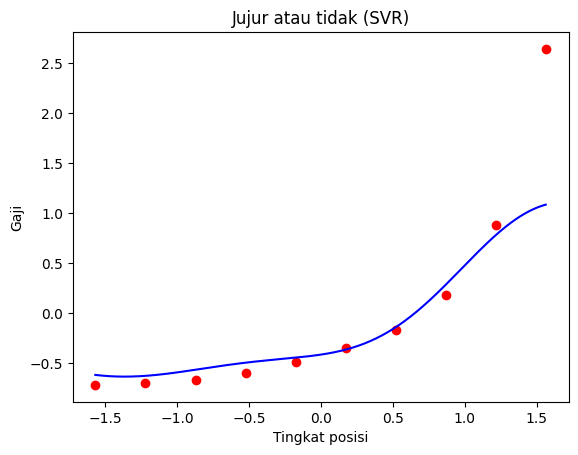

In [ ]:
# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

In [ ]:
# Prediksi hasil
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])
# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

In [ ]:
# Menampilkan hasil prediksi
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


In [ ]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


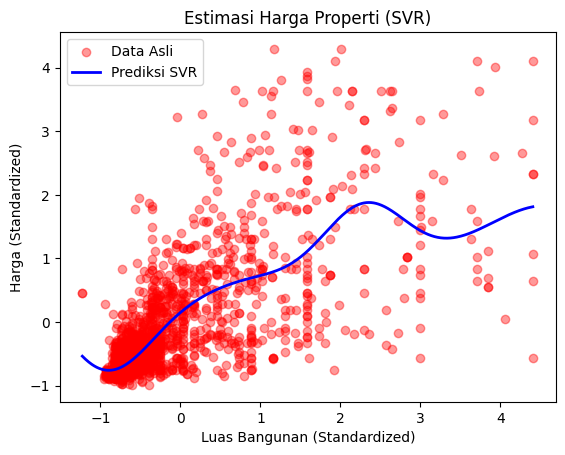

In [2]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Mengimpor dataset properti_multi_kota.csv
dataset = pd.read_csv('properti_multi_kota.csv')

# Imputasi missing value & filter outlier ekstrem agar kurva SVR terbaca jelas
dataset['luas_bangunan'] = dataset['luas_bangunan'].fillna(dataset['luas_bangunan'].median())
dataset = dataset[
    (dataset['luas_bangunan'] > 0) & (dataset['luas_bangunan'] <= dataset['luas_bangunan'].quantile(0.95)) &
    (dataset['harga'] > 1e7) & (dataset['harga'] <= dataset['harga'].quantile(0.95))
].copy()

# Ambil sampel 1500 data agar training SVR cepat dan ringan
dataset_sample = dataset.sample(n=min(1500, len(dataset)), random_state=42)

# Memilih fitur X (luas_bangunan) dan target y (harga)
X = dataset_sample[['luas_bangunan']].values
y = dataset_sample['harga'].values

# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y.ravel())

# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
# Perbaikan: Menggunakan X.min() dan X.max() untuk mendapatkan nilai skalar tunggal
X_grid = np.arange(X.min(), X.max(), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red', alpha=0.4, label='Data Asli')
plt.plot(X_grid, regressor.predict(X_grid), color='blue', linewidth=2, label='Prediksi SVR')
plt.title('Estimasi Harga Properti (SVR)')
plt.xlabel('Luas Bangunan (Standardized)')
plt.ylabel('Harga (Standardized)')
plt.legend()
plt.show()

In [3]:
# Prediksi hasil untuk luas bangunan 120 m2
luas_prediksi = np.array([[120.0]])

# Penskalaan fitur untuk data yang akan diprediksi
luas_prediksi_scaled = sc_X.transform(luas_prediksi)

# Melakukan prediksi menggunakan model SVR
harga_prediksi_scaled = regressor.predict(luas_prediksi_scaled)

# Kembalikan hasil prediksi ke skala aslinya (Rupiah)
harga_prediksi = sc_y.inverse_transform(harga_prediksi_scaled.reshape(-1, 1))

# Menampilkan hasil prediksi
print(f"Prediksi Harga untuk Luas Bangunan 120 m2: Rp {harga_prediksi[0][0]:,.2f}")

Prediksi Harga untuk Luas Bangunan 120 m2: Rp 1,650,339,141.69


In [4]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.4583832223960964
MSE: 0.49504727566245127
RMSE: 0.7035959605216984
R-squared: 0.5049527243375487
